# Multiclass Logistic Regression

## Apple, orange, or banana?

A fruit sorter chooses one identity from three classes. The synthetic measurements are hue $x_1$ in degrees and length divided by width $x_2$. This restricted example contains red apples, oranges, and yellow bananas: apples and oranges are mostly round, while bananas are elongated.

Multiclass logistic regression learns a different linear score for each class $k$:

$$
z_k=b_k+w_{k1}x_1+w_{k2}x_2.
$$

The intercept $b_k$ and weights $w_{k1},w_{k2}$ determine how the same measurements support that class. Softmax converts the three scores into competing probabilities:

$$
p_k=\frac{e^{z_k}}{\sum_{j=1}^{3}e^{z_j}}, \qquad
\sum_{k=1}^{3}p_k=1, \qquad \hat y=\underset{k}{\arg\max}\;p_k.
$$

The denominator adds the positive exponential scores of all three classes. Each probability is a share of that total. The largest probability determines the predicted fruit; an exact tie uses the class order Apple, Orange, Banana.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/03_softmax_probabilities.png" alt="A fruit with hue 50 degrees and length divided by width 2.8 produces three learned scores and softmax probabilities; the largest identifies the predicted class." width="512" style="max-width:100%;height:auto;">

One-hot encoding represents the observed class with one at its position and zero elsewhere. With this class order, an orange has target vector $(0,1,0)$. Predicted probabilities remain continuous values rather than a one-hot vector.


## Fitting and crossing a boundary

For one fruit, multiclass cross-entropy uses the probability assigned to its observed class:

$$
\ell=-\sum_{k=1}^{3}y_k\log p_k=-\log p_{\text{observed class}}.
$$

Here, $y_k$ is the one-hot target. Only the observed class contributes a term. Gradient descent fits the coefficients by reducing mean training loss. Scaling uses training means and standard deviations; validation fruit are excluded from both scaling and fitting.

The controls describe a new fruit. The star marks its hue and shape, the background shows the model's predicted classes, and colored points show labeled training fruit. The probabilities and regions come from the same fitted model.

Crossing a boundary changes the predicted identity, although probabilities vary smoothly. Between two classes $a$ and $b$, equal probabilities occur when $z_a=z_b$. Because these scores are linear in the inputs, their pairwise boundary is a straight line.


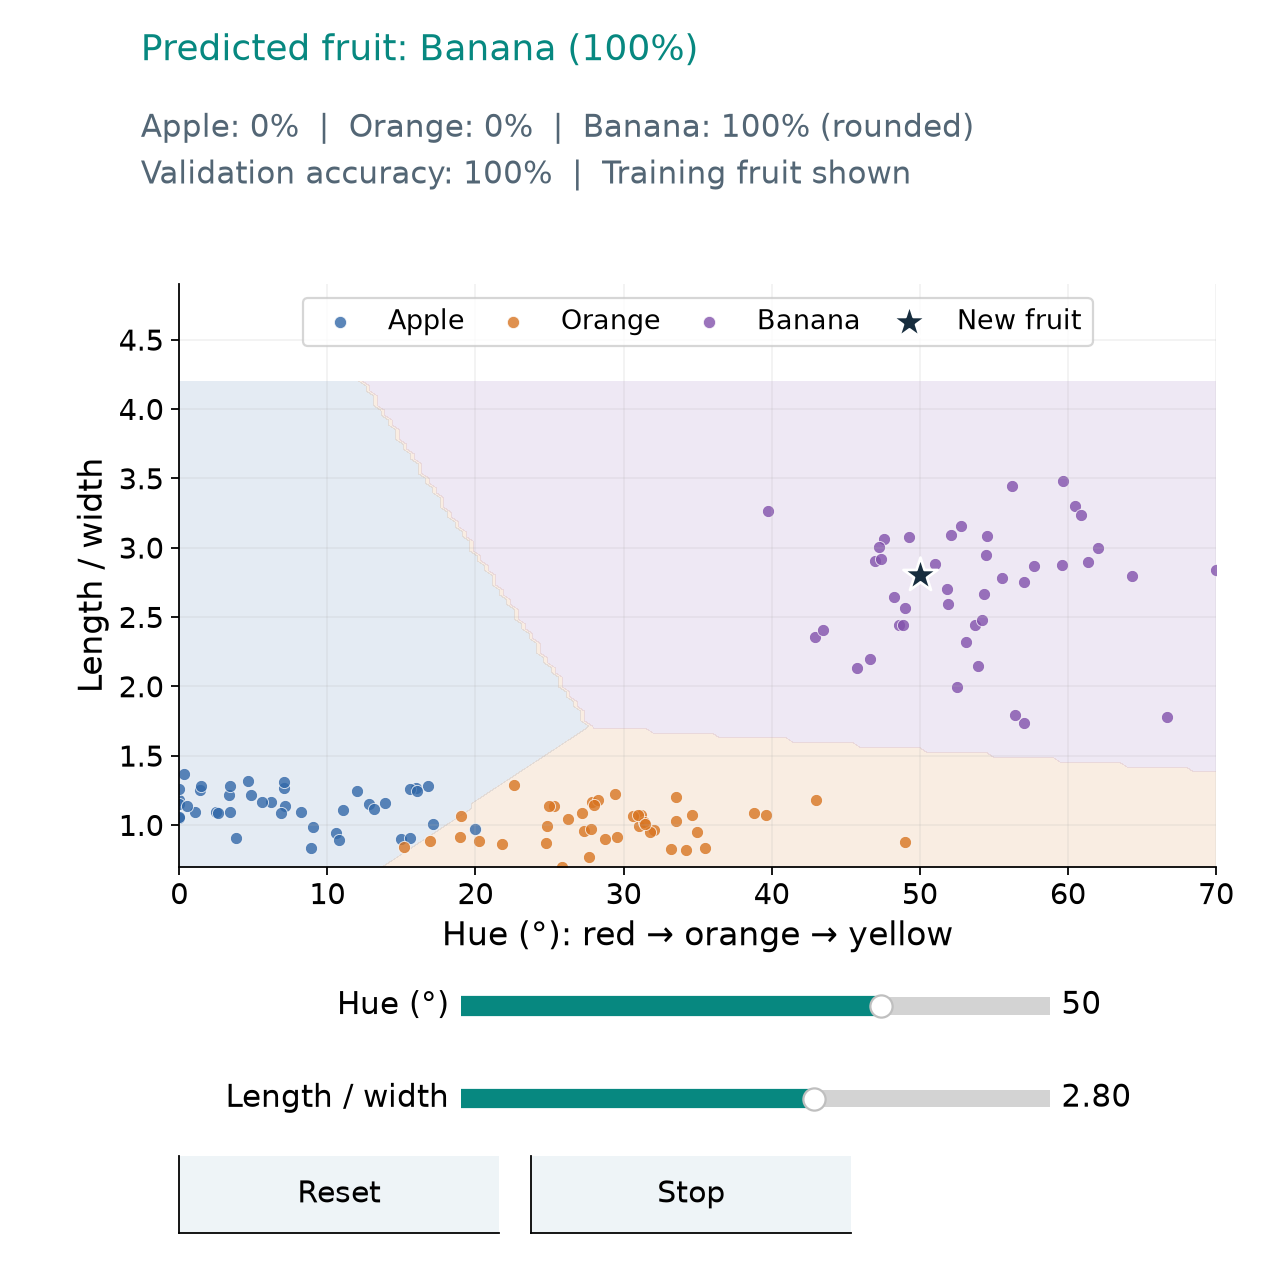

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=14, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.78 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .25 / height, width, .48 / height]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 * height - .78)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()



def make_messages(seed, count=240, spam_fraction=.35):
    """Synthetic labels and counts; no real messages or URLs are collected."""
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    """Synthetic fruit measurements: hue in degrees and length / width."""
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

fruit, labels = make_fruit(71)
class_names = np.array(["Apple", "Orange", "Banana"])
class_colors = [BLUE, ORANGE, PURPLE]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=71)
feature_mean, feature_scale = fruit[train_id].mean(axis=0), fruit[train_id].std(axis=0)


def fruit_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


train_features = fruit_features(fruit[train_id])
one_hot = np.eye(3)[labels[train_id]]
weights = np.zeros((3, 3))
for iteration in range(2500):
    probability = softmax(train_features @ weights)
    weights -= .15 * train_features.T @ (probability - one_hot) / len(train_id)
validation_probability = softmax(fruit_features(fruit[validation_id]) @ weights)
validation_accuracy = np.mean(validation_probability.argmax(axis=1) == labels[validation_id])
hue_grid, shape_grid = np.meshgrid(np.linspace(0, 70, 141), np.linspace(.7, 4.2, 101))
region_probability = softmax(fruit_features(np.c_[hue_grid.ravel(), shape_grid.ravel()]) @ weights)
regions = region_probability.argmax(axis=1).reshape(hue_grid.shape)


def render_fruit(view, hue, shape):
    scores = (fruit_features([[hue, shape]]) @ weights)[0]
    probability = softmax(scores)
    predicted = int(probability.argmax())
    ax = view.ax
    ax.contourf(hue_grid, shape_grid, regions, levels=[-.5, .5, 1.5, 2.5],
                colors=class_colors, alpha=.13)
    for index, (name, color) in enumerate(zip(class_names, class_colors)):
        selected = train_id[labels[train_id] == index]
        ax.scatter(fruit[selected, 0], fruit[selected, 1], color=color, s=30,
                   edgecolor="white", linewidth=.4, label=name, alpha=.8)
    ax.scatter([hue], [shape], color="#172d3e", marker="*", s=260,
               edgecolor="white", linewidth=1.2, zorder=5, label="New fruit")
    ax.set(xlim=(0, 70), ylim=(.7, 4.9), xlabel="Hue (°): red → orange → yellow",
           ylabel="Length / width")
    ax.legend(loc="upper center", ncol=4, fontsize=12, columnspacing=.8)
    view.status.set_text(f"Predicted fruit: {class_names[predicted]} ({probability[predicted]:.0%})")
    view.detail.set_text("  |  ".join(f"{name}: {p:.0%}" for name, p in zip(class_names, probability))
                         + f" (rounded)\nValidation accuracy: {validation_accuracy:.0%}  |  Training fruit shown")
    return {"probability": probability, "scores": scores, "prediction": predicted,
            "query": np.array([hue, shape])}


fruit_demo = ClassificationExplorer("fruit", render_fruit, [
    ("hue", "Hue (°)", 0, 70, 50, 1, "%0.0f"),
    ("shape", "Length / width", .7, 4.2, 2.8, .05, "%0.2f"),
])
fruit_demo.start()


## A fruit outside the available classes

Softmax chooses among the three available classes. It has no automatic “unknown” label for a pear, and even a confident prediction can be wrong. Color changes with ripeness and lighting; green apples are outside this dataset's stated coverage.

Some apples and oranges overlap in color and shape. More measurements may help distinguish them. Validation accuracy describes only these separate synthetic fruit, and it does not measure calibration or performance on a real sorting line.
